# Week 2 · Part C

This notebook is Part C of the Week 2 assignment. It has two parts:

* **C1 · How the gradient depends on the loss** — SymPy derives the gradient of a small MLP symbolically, and you look at how the derivative of each parameter changes as the loss grows. Needs only NumPy, SymPy and Matplotlib.
* **C2 · Training an MLP on MNIST** — the seven steps of the handout in PyTorch, with early stopping. Needs PyTorch and torchvision (Colab has both).

**How to work.** The structure, the definitions and the parameter values are given. Cells marked `# TODO` are yours: write them yourself or with an AI coding assistant (e.g. Codex). Run every cell, check that it does what the text asks, and be able to explain every line. Answer the questions at the end of each part in your report, together with your figures.

Run the notebook from top to bottom. The two parts are independent: C1 does not use PyTorch, so it also runs on its own.

## C1 · How the gradient depends on the loss

You will let SymPy derive the gradient of a small MLP symbolically, then see how the derivative of each parameter changes as the loss grows.

Handout references: Step 4 (model), Step 5 (loss), Step 6 (gradient and backpropagation).

In [7]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

### The network

One input $x$, one hidden layer of 2 units, one output:

$$h_1 = a[\beta_{01} + \omega_{01}x], \qquad h_2 = a[\beta_{02} + \omega_{02}x], \qquad f = \beta_1 + \omega_{11}h_1 + \omega_{12}h_2 .$$

This is the network of handout Step 4 with $\boldsymbol\Omega_0 = (\omega_{01}, \omega_{02})^\top$, $\boldsymbol\beta_0 = (\beta_{01}, \beta_{02})^\top$, $\boldsymbol\Omega_1 = (\omega_{11}, \omega_{12})$; it has 7 parameters.

**Configurations.** The activation $a[\cdot]$ is `tanh` or ReLU. The loss is

* squared error, $\ell = (f - y)^2$ (regression), or
* binary cross-entropy, $p = \mathrm{sig}[f] = 1/(1+e^{-f})$, $\ \ell = -[\,y\log p + (1-y)\log(1-p)\,]$ (classification).

Required: (i) tanh + squared error, (ii) tanh + binary cross-entropy, (iii) ReLU + squared error. Optional: (iv) ReLU + binary cross-entropy.

The symbols and the parameter values are defined in the next cell. Do not change the values.

In [8]:
# input, target and the 7 parameters as SymPy symbols
x, y = sp.symbols('x y', real=True)
w01, w02, b01, b02, w11, w12, b1 = sp.symbols(
    'omega_01 omega_02 beta_01 beta_02 omega_11 omega_12 beta_1', real=True)
params = [w01, w02, b01, b02, w11, w12, b1]

# fixed values used for all plots
values = {x: 1.5, w01: 0.6, w02: -0.5, b01: 0.5, b02: 0.2, w11: 0.8, w12: -0.6, b1: 0.1}

configs = [("tanh", "se"), ("tanh", "bce"), ("relu", "se")]   # add ("relu", "bce") if you like

### Task 1 · Symbolic output, loss and derivatives

Write two functions:

* `make_output(activation)` returns the symbolic output $f$ for `activation` = `"tanh"` or `"relu"`. ReLU can be written as `sp.Max(0, z)`.
* `make_loss(f, loss)` returns the symbolic loss $\ell$ for `loss` = `"se"` (squared error) or `"bce"` (binary cross-entropy).

Then, for every configuration, use `sp.diff` to get the derivative of $\ell$ with respect to each of the 7 parameters and print them.

In [9]:
def make_output(activation):
    # Build the two hidden units, then combine them into the scalar output f.
    z1 = b01 + w01 * x
    z2 = b02 + w02 * x
    if activation == "tanh":
        h1, h2 = sp.tanh(z1), sp.tanh(z2)
    elif activation == "relu":
        h1, h2 = sp.Max(0, z1), sp.Max(0, z2)
    else:
        raise ValueError("activation must be 'tanh' or 'relu'")
    return b1 + w11 * h1 + w12 * h2


def make_loss(f, loss):
    # Return squared error or binary cross-entropy for output f and target y.
    if loss == "se":
        return (f - y) ** 2
    elif loss == "bce":
        p = 1 / (1 + sp.exp(-f))
        return -(y * sp.log(p) + (1 - y) * sp.log(1 - p))
    else:
        raise ValueError("loss must be 'se' or 'bce'")

In [10]:
losses = {}   # (activation, loss) -> symbolic loss
derivs = {}   # (activation, loss) -> {parameter: symbolic derivative}

for act, lname in configs:
    f = make_output(act)
    ell = make_loss(f, lname)
    losses[(act, lname)] = ell
    derivs[(act, lname)] = {param: sp.diff(ell, param) for param in params}
    print(f"\nConfiguration: {act} + {lname}")
    print("f =", f)
    print("loss =", ell)
    for param in params:
        print(f"d(loss)/d({param}) =", derivs[(act, lname)][param])


Configuration: tanh + se
f = beta_1 + omega_11*tanh(beta_01 + omega_01*x) + omega_12*tanh(beta_02 + omega_02*x)
loss = (beta_1 + omega_11*tanh(beta_01 + omega_01*x) + omega_12*tanh(beta_02 + omega_02*x) - y)**2
d(loss)/d(omega_01) = 2*omega_11*x*(1 - tanh(beta_01 + omega_01*x)**2)*(beta_1 + omega_11*tanh(beta_01 + omega_01*x) + omega_12*tanh(beta_02 + omega_02*x) - y)
d(loss)/d(omega_02) = 2*omega_12*x*(1 - tanh(beta_02 + omega_02*x)**2)*(beta_1 + omega_11*tanh(beta_01 + omega_01*x) + omega_12*tanh(beta_02 + omega_02*x) - y)
d(loss)/d(beta_01) = 2*omega_11*(1 - tanh(beta_01 + omega_01*x)**2)*(beta_1 + omega_11*tanh(beta_01 + omega_01*x) + omega_12*tanh(beta_02 + omega_02*x) - y)
d(loss)/d(beta_02) = 2*omega_12*(1 - tanh(beta_02 + omega_02*x)**2)*(beta_1 + omega_11*tanh(beta_01 + omega_01*x) + omega_12*tanh(beta_02 + omega_02*x) - y)
d(loss)/d(omega_11) = 2*(beta_1 + omega_11*tanh(beta_01 + omega_01*x) + omega_12*tanh(beta_02 + omega_02*x) - y)*tanh(beta_01 + omega_01*x)
d(loss)/d(omeg

### Task 2 · Check one derivative with the chain rule

For configuration (i), the chain rule (handout Step 6) gives

$$\frac{\partial \ell}{\partial \omega_{01}} = 2(f - y)\,\omega_{11}\,a'[z_1]\,x, \qquad z_1 = \beta_{01} + \omega_{01}x, \qquad a'[z] = 1 - \tanh^2 z .$$

Write this expression in SymPy and show that its difference from SymPy's derivative simplifies to 0.

In [11]:
# TODO: hand-written chain-rule expression for d l / d omega_01 in configuration (i),
#       then print sp.simplify(hand - derivs[("tanh", "se")][w01])


# Chain rule for configuration (i): tanh activation and squared error.
f_tanh = make_output("tanh")
z1 = b01 + w01 * x
hand = 2 * (f_tanh - y) * w11 * (1 - sp.tanh(z1)**2) * x
difference = sp.simplify(hand - derivs[("tanh", "se")][w01])
print("Chain-rule expression:", hand)
print("Difference from SymPy derivative:", difference)

Chain-rule expression: omega_11*x*(1 - tanh(beta_01 + omega_01*x)**2)*(2*beta_1 + 2*omega_11*tanh(beta_01 + omega_01*x) + 2*omega_12*tanh(beta_02 + omega_02*x) - 2*y)
Difference from SymPy derivative: 0


### Task 3 · Make the loss vary

Keep the network fixed and change only what makes the loss larger or smaller:

* **Squared error:** substitute all parameter values and sweep the target $y$ from $-3$ to $3$.
* **Binary cross-entropy:** set the label $y = 1$, substitute all values except $\beta_1$, and sweep $\beta_1$ from $-6$ to $6$ (so $p$ moves from near 0 to near 1).

For each configuration, return the loss values along the sweep and the values of every derivative along the same sweep. `sp.lambdify` turns an expression into a NumPy function. (Careful: a derivative that is a constant gives a single number; broadcast it to the length of the sweep.)

In [15]:
def sweep(act, lname, n=400):
    # For squared error vary y; for BCE fix y=1 and vary the output bias beta_1.
    if lname == "se":
        sweep_symbol = y
        sweep_values = np.linspace(-3, 3, n)
        substitutions = values.copy()
    elif lname == "bce":
        sweep_symbol = b1
        sweep_values = np.linspace(-6, 6, n)
        substitutions = {**values, y: 1}
        substitutions.pop(b1)
    else:
        raise ValueError("loss must be 'se' or 'bce'")

    # Map ReLU's symbolic derivative at the kink to NumPy for lambdify.
    modules = [{"Heaviside": lambda z: np.heaviside(z, 0.5)}, "numpy"]

    def evaluate(expr):
        expr = expr.subs(substitutions)
        fn = sp.lambdify(sweep_symbol, expr, modules=modules)
        result = np.asarray(fn(sweep_values), dtype=float)
        if result.ndim == 0:
            result = np.full(sweep_values.shape, float(result))
        return result

    loss_values = evaluate(losses[(act, lname)])
    derivative_values = {param: evaluate(expr)
                         for param, expr in derivs[(act, lname)].items()}
    return loss_values, derivative_values


### Task 4 · Plot the derivatives against the loss

For each configuration make one figure: horizontal axis the loss value $\ell$, vertical axis the derivative, one curve per parameter. Include at least one weight and one bias of each layer, e.g. $\omega_{01}, \beta_{01}, \omega_{12}, \beta_1$ (you may plot all 7). Label the axes, give each figure a title naming the configuration, and add a legend. Use these figures in your report.

For configuration (iii), plot all 7 parameters: question 4 below asks which derivatives are zero, and only one of the four listed above ($\omega_{12}$) is one of them.

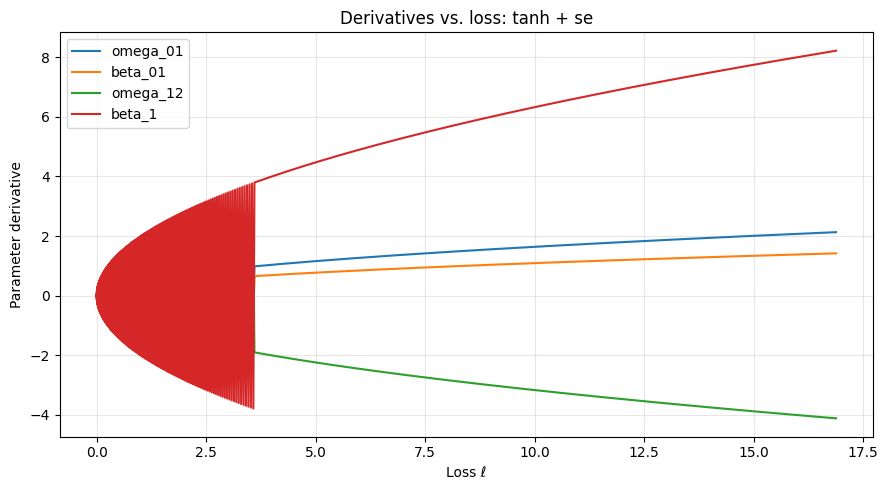

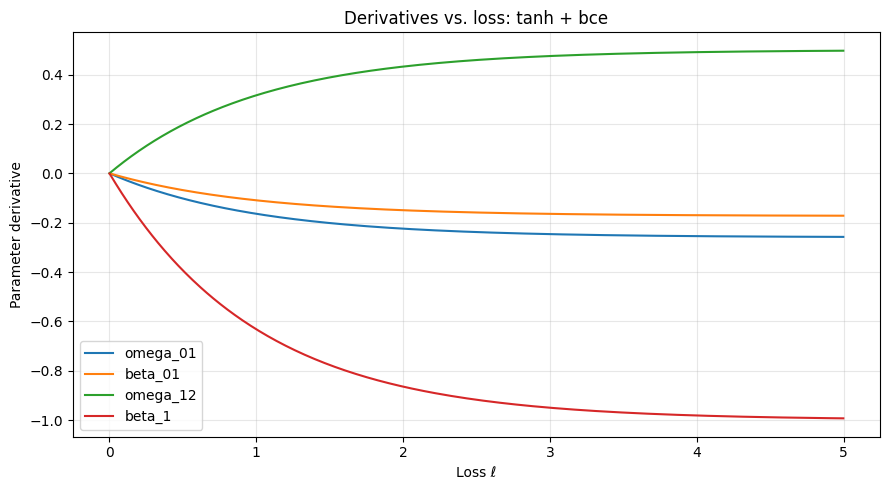

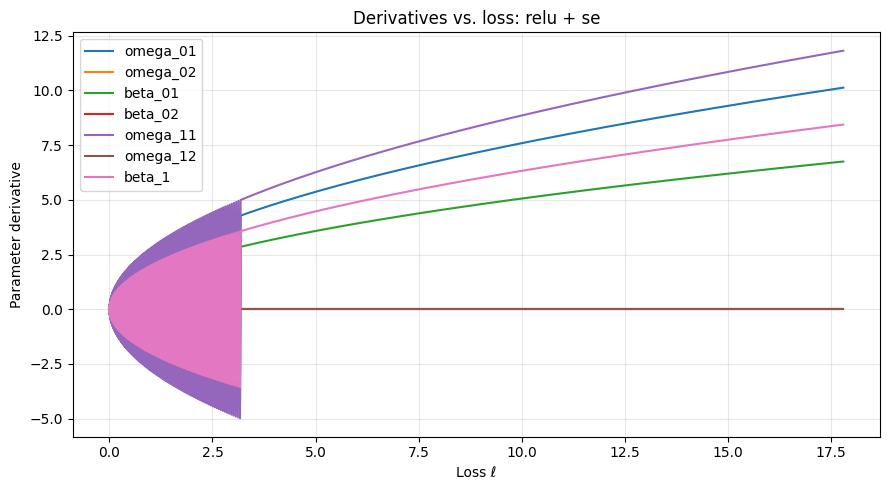

In [16]:
plot_params = [w01, b01, w12, b1]   # weight and bias from both layers

for act, lname in configs:
    loss_values, derivative_values = sweep(act, lname)
    # The ReLU + squared-error figure shows all seven parameters as required.
    params_to_plot = params if (act, lname) == ("relu", "se") else plot_params
    order = np.argsort(loss_values)

    plt.figure(figsize=(9, 5))
    for param in params_to_plot:
        plt.plot(loss_values[order], derivative_values[param][order],
                 label=str(param), linewidth=1.5)
    plt.xlabel("Loss ℓ")
    plt.ylabel("Parameter derivative")
    plt.title(f"Derivatives vs. loss: {act} + {lname}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


### Questions C1 (answer in your report)

1. For squared error, how does the size of the derivatives change as the loss grows? Why does each curve have two branches? (Hint: write $\ell$ and $\partial\ell/\partial\beta_1$ in terms of the error $f - y$.)
2. For binary cross-entropy, how does the size of the derivatives change as the loss grows? How does this differ from squared error when the loss is large?
3. Compare the curves of different parameters within one figure. Why do they have the same shape and differ only in scale and sign? Use the chain rule.
4. In configuration (iii), some derivatives are zero for every $y$. Which ones, and why? Compare with configuration (i).
5. Together, what do these results say about which training examples drive the parameter updates?

## C2 · Training an MLP on MNIST

You will train an MLP to classify handwritten digits, following the seven steps of the handout: data, split, batches and epochs, model, loss, optimizer, convergence and testing.

**Your own comments.** In this part, add **your own comments** to the key lines, explaining in your own words what each line does and which handout step it belongs to, e.g. `# Step 3: shuffle=True gives new batch combinations every epoch`. Key lines: the data split, the data loader with shuffling, the model definition, the loss, `optimizer.zero_grad()`, `loss.backward()`, `optimizer.step()`, the validation loop, and saving the best parameters.

Use the loss figure of this part in your report.

In [17]:
import copy
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


### Steps 1–2 · Data and split

Load MNIST with `torchvision.datasets.MNIST` (`transforms.ToTensor()` scales the pixels to $[0, 1]$). Split the 60,000 training images into 50,000 for training and 10,000 for validation with `random_split` (use a fixed generator so the split is reproducible). Keep the 10,000 test images for the very end. Print the three sizes.

In [20]:
# TODO: train_full, test_set = MNIST training and test sets
# TODO: train_set, val_set = random split of train_full into 50,000 / 10,000


# Step 1: Load the MNIST training and test data; ToTensor scales image pixels to [0, 1].
transform = transforms.ToTensor()
train_full = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_set = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

# Step 2: Split the 60,000 training images reproducibly into 50,000 train and 10,000 validation images.
split_generator = torch.Generator().manual_seed(0)
train_set, val_set = random_split(train_full, [50_000, 10_000], generator=split_generator)

print("Training images:", len(train_set))
print("Validation images:", len(val_set))
print("Test images:", len(test_set))

100%|██████████| 9.91M/9.91M [00:00<00:00, 105MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 3.21MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 26.0MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.04MB/s]


Training images: 50000
Validation images: 10000
Test images: 10000


### Step 3 · Batches and epochs

Create three `DataLoader`s. Only the training loader shuffles. Print how many iterations one epoch has.

In [21]:
BATCH_SIZE = 100

# TODO: train_loader (shuffle=True), val_loader, test_loader

# Step 3A: Shuffle training examples so batches come in a new order each epoch.
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
# Step 3B: Keep validation and test batches in a fixed order for evaluation.
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

print("Training iterations per epoch:", len(train_loader))

Training iterations per epoch: 500


### Step 4 · Model

Define an MLP: flatten the $28\times28$ image to 784 values, at least one hidden layer with ReLU, and 10 outputs (one per digit). The outputs are the raw values $\mathbf f$; do not add a softmax, because the loss below applies it. Print the number of parameters.

In [22]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: layers
        # Step 4A: Flatten each 28x28 image and map 784 pixels to 128 hidden features.
        self.flatten = nn.Flatten()
        self.hidden = nn.Linear(28 * 28, 128)
        self.relu = nn.ReLU()
        # Step 4B: Map hidden features to 10 raw scores, one for each digit.
        self.output = nn.Linear(128, 10)

    def forward(self, x):
        # TODO: forward pass, returns 10 raw outputs per image
        # Step 4C: Apply the layers in order; return raw scores for CrossEntropyLoss.
        x = self.flatten(x)
        x = self.relu(self.hidden(x))
        return self.output(x)


model = MLP().to(device)
# TODO: print the number of parameters
print("Number of parameters:", sum(p.numel() for p in model.parameters()))

Number of parameters: 101770


### Steps 5–6 · Loss and optimizer

Use the cross-entropy loss (`nn.CrossEntropyLoss`) and SGD or Adam. Choose a learning rate.

In [23]:
# TODO: loss_fn, optimizer

# Step 5: Cross-entropy compares the 10 raw digit scores with the correct labels.
loss_fn = nn.CrossEntropyLoss()

# Step 6: Adam updates the model parameters using gradients, with learning rate 0.001.
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

### One epoch of training, and evaluation

* `train_one_epoch(model, loader, loss_fn, optimizer)` runs over all training batches; for each batch: forward pass, loss, `zero_grad`, `backward`, `step`. It returns the average training loss of the epoch.
* `evaluate(model, loader, loss_fn)` computes the average loss and the accuracy on a data set without changing the parameters (`model.eval()` and `torch.no_grad()`).

Everything the two functions use is passed in as an argument, except `device`, which is global.

In [24]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    total_loss = 0.0
    total_examples = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = loss_fn(outputs, labels)
        # Step 6: Clear gradients left over from the previous batch.
        optimizer.zero_grad()
        # Step 6: Backpropagation calculates each parameter's gradient.
        loss.backward()
        # Step 6: Update the parameters using their gradients.
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        total_examples += labels.size(0)

    return total_loss / total_examples


def evaluate(model, loader, loss_fn):
    # Step 7A: Use evaluation mode and turn off gradients while validating or testing.
    model.eval()
    total_loss = 0.0
    total_examples = 0
    correct = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            total_loss += loss.item() * labels.size(0)
            total_examples += labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()

    average_loss = total_loss / total_examples
    accuracy = correct / total_examples
    return average_loss, accuracy

### Step 7 · Training loop with early stopping

Train for enough epochs that the training loss flattens out (e.g. 30). After every epoch, record the training loss, the validation loss and the validation accuracy (the three lists of `history`), and keep a copy of the parameters (`copy.deepcopy(model.state_dict())`) whenever the validation loss reaches a new minimum.

In [25]:
EPOCHS = 30
history = {"train_loss": [], "val_loss": [], "val_acc": []}
best_val, best_epoch, best_state = float("inf"), None, None

# Step 7B: Train and validate once per epoch, recording each epoch's results.
for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
    # Step 7C: Check validation performance without updating the model.
    val_loss, val_acc = evaluate(model, val_loader, loss_fn)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    # Step 7D: Keep a separate copy whenever validation loss reaches a new low.
    if val_loss < best_val:
        best_val = val_loss
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())

    print(f"Epoch {epoch:2d}/{EPOCHS} | "
          f"train loss: {train_loss:.4f} | "
          f"val loss: {val_loss:.4f} | val accuracy: {val_acc:.2%}")

print(f"Best validation loss: {best_val:.4f} at epoch {best_epoch}")

Epoch  1/30 | train loss: 0.4133 | val loss: 0.2403 | val accuracy: 93.13%
Epoch  2/30 | train loss: 0.1950 | val loss: 0.1761 | val accuracy: 94.72%
Epoch  3/30 | train loss: 0.1422 | val loss: 0.1410 | val accuracy: 95.95%
Epoch  4/30 | train loss: 0.1093 | val loss: 0.1212 | val accuracy: 96.39%
Epoch  5/30 | train loss: 0.0878 | val loss: 0.1058 | val accuracy: 96.91%
Epoch  6/30 | train loss: 0.0730 | val loss: 0.0985 | val accuracy: 97.12%
Epoch  7/30 | train loss: 0.0603 | val loss: 0.0966 | val accuracy: 97.07%
Epoch  8/30 | train loss: 0.0512 | val loss: 0.0921 | val accuracy: 97.20%
Epoch  9/30 | train loss: 0.0434 | val loss: 0.0902 | val accuracy: 97.33%
Epoch 10/30 | train loss: 0.0367 | val loss: 0.0895 | val accuracy: 97.28%
Epoch 11/30 | train loss: 0.0304 | val loss: 0.0900 | val accuracy: 97.33%
Epoch 12/30 | train loss: 0.0263 | val loss: 0.0904 | val accuracy: 97.32%
Epoch 13/30 | train loss: 0.0218 | val loss: 0.0866 | val accuracy: 97.54%
Epoch 14/30 | train loss:

Plot the training and validation loss against the epoch in one figure and mark the epoch kept by early stopping. Use this figure in your report.

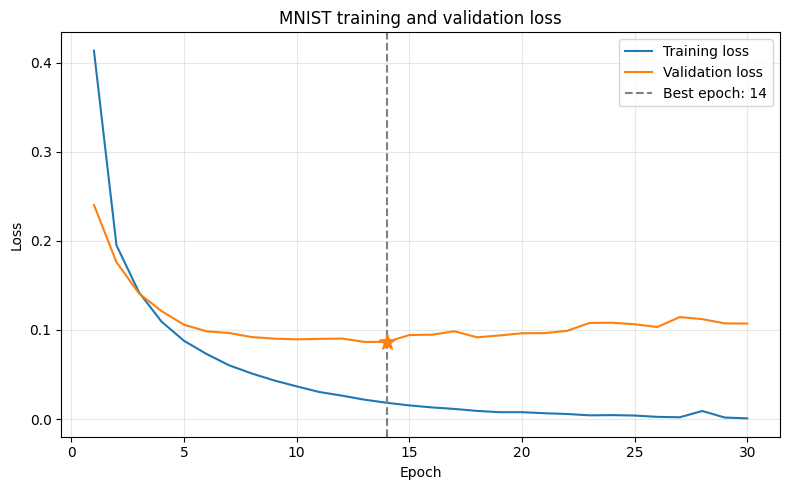

In [26]:
# Step 7: Plot both losses over training and mark the epoch with the lowest validation loss.
epochs = range(1, len(history["train_loss"]) + 1)
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], label="Training loss")
plt.plot(epochs, history["val_loss"], label="Validation loss")
plt.axvline(best_epoch, color="gray", linestyle="--",
            label=f"Best epoch: {best_epoch}")
plt.scatter(best_epoch, history["val_loss"][best_epoch - 1],
            color="tab:orange", marker="*", s=140, zorder=3)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MNIST training and validation loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Test, once

Load the best parameters and compute the test loss and test accuracy. Run this cell only once, at the end.

In [27]:
# TODO: model.load_state_dict(best_state); evaluate on test_loader; print the results

# Step 7: Restore the parameters saved from the epoch with the lowest validation loss.
model.load_state_dict(best_state)

# Step 7: Evaluate on the held-back test set once, using the selected parameters.
test_loss, test_acc = evaluate(model, test_loader, loss_fn)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.2%}")

Test loss: 0.0759
Test accuracy: 97.88%


### Questions C2 (answer in your report)

1. Show the loss figure. When does the training loss converge? Does the validation loss rise later? At which epoch did early stopping keep the parameters, and what is the test accuracy?
2. Make a short table that maps each of the seven handout steps to the lines of your code that implement it.
3. Explain what `loss.backward()` and `optimizer.step()` compute, in terms of handout Step 6. Why is `optimizer.zero_grad()` needed?
4. How did you check that the code written with the AI assistant is correct? Name one thing you had to fix or verify.